## Problem information 

# Introduction to the Problem: Classification of American Alphabet Letters Using CNN

## Dataset Description

The dataset used in this project contains images representing the letters of the American alphabet (from "A" to "Z") through hand signs performed with a single hand. This dataset is specifically curated for addressing multi-class classification problems and is ideal for applying advanced techniques such as Convolutional Neural Networks (CNN).

### Dataset Features:
- **Classes:** 26 categories corresponding to each letter of the American alphabet.
- **Format:** Images depicting hand signs for each letter.
- **Purpose:** Train a multi-class classification model to accurately identify the sign corresponding to each letter.

## Project Objective

The main goal is to develop a model based on Convolutional Neural Networks (CNN) capable of correctly classifying the images in the dataset into one of the 26 available categories, achieving an accuracy close to 98% if the algorithm is well-designed and trained.

### Potential Applications:
- **Accessibility:** Enhancing communication for individuals with hearing disabilities through automatic interpretation of sign language.
- **Education:** Interactive tool for teaching the American alphabet in sign language.
- **Visual Recognition:** Advancements in automatic gesture and sign recognition systems.


## Table of Contents

1. Define the transformation applied to the images of the data set 
   - We resize the images to 28 x28
   - normalize the images to force pixels to be in [-1,1]

2. Load data set 
   - Split train and test using data loaders as they are tensors
   - Print the number of samples we have 

3. Create the architecture of the CNN 
   - With two Convolutional layers 
   - 2 max pooling   first phase 
   - Flatten 
   - 2 fully connected layers for final classification  

4. Initiate the parameters 
   - Criterion 
   - Optimizer 
   - n of epochs 
   - learning rate 

5. Train the model and evaluated 

6. Hyperparameters 
   - Learning rate 
   - batch size
   - N of epochs 
   - CNN architecture (N filters , kernel , N layers,Stride )
   - Activation function 
   - Loss function and optimizers

7. Conclusions 





## 1. Define transformation
1. 28 x 28 pixels the images ( a standard size )
2. Interval of pixels from 1 to -1 

In [ ]:
  # Import necessary libraries
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Define transformation: resizing, converting to tensor, and normalizing images
transform = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)) # change interval from [0, 1] to [-1, 1]
])

## 2. Load data set 
1. load: Letters_data 
2. Train and test split (80% train , 20% test)
3. Use data loader to manage tensors , train and test loaders 


In [ ]:


# Load dataset from directory structure (assuming folders named a,b ,c,...,z)
dataset = datasets.ImageFolder(root='../data/Letters_data', transform=transform)

# Split dataset into training and testing sets (80% train, 20% test)
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size
train_dataset, test_dataset = random_split(dataset, [train_size, test_size])

# Create data loaders for training and testing datasets
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Print dataset sizes for verification
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of testing samples: {len(test_dataset)}")

Number of training samples: 1452
Number of testing samples: 363


In [ ]:
import torch.nn as nn
num_classes = len(dataset.classes)

## 3. CNN architecture 
1. input dim : 28 x 28 x 3 , output wanted : num_clases 
2. First Conv : K = 3 , S =1 , P = 1 -> 28 x 28 x 32
2. First Max pool : K= 2, S = 2 ->  14 x 14 x 32
3. Second Conv : K = 3 , S =1 , P = 1 -> 14 x 14 x 64
4. Second max pool : K= 2, S = 2 -> 7 x 7 x 64
5. Flatten : = 64 * 7 * 7 = 3136
6. First Fc1 : -> 128
7. Second Fc2 : -> num_clases 

In [ ]:
class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        # fisrt phase of characteristics extraction
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1) # output (batch_size, 32, 28, 28)
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2) #output (batch_size, 32, 14, 14)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=32,  out_channels=64, kernel_size=3, stride=1, padding=1) # output (batch_size, 64, 14, 14)

        # Second phase of classification

        self.fc1 = nn.Linear( in_features=64*7*7, out_features=128)
        self.fc2 = nn.Linear(in_features=128, out_features=num_classes) # output = num_classes

        
    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.maxpool(x)

        x = self.relu(self.conv2(x))
        x = self.maxpool(x)

        x = x.view(x.size(0), -1) # flatten the tensor

        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x


In [ ]:
# Instantiate and print the model structure
model = CNNModel()
print(model)

CNNModel(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (maxpool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=26, bias=True)
)


## Initiate parameters 
1. Criterion : CrossEntropyLoss
2. Optimizer : Adam 
3. N_epochs = 10 ( to try and se how its get on in fast training )
4. Learning rate : 0.001

In [ ]:
import torch.optim as optim

# Set the device to GPU if available, otherwise CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# Number of epochs for training
n_epochs = 10

#Learming rate 
lr = 0.001


## Train and evaluate the model
 1. Define the train function 
 2. Define the evaluate function 
 And get the final accuracy of all the epochs of your model  

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Set the device to GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()  # Suitable for multi-class classification
optimizer = optim.Adam(model.parameters(), lr=0.001)

def train(model, train_loader, optimizer, criterion, device):
    """
    Training function for one epoch.
    - model: the neural network model
    - train_loader: DataLoader for training data
    - optimizer: optimizer to update model parameters
    - criterion: loss function
    - device: computing device (GPU or CPU)

    Returns:
    - Average loss for the epoch.
    """
    model.train()  # Set model to training mode
    running_loss = 0.0
    # Iterate over training batches
    for inputs, labels in train_loader:
        # Move data to the selected device
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()  # Zero the parameter gradients
        outputs = model(inputs)  # Forward pass: compute predicted outputs
        loss = criterion(outputs, labels)  # Compute loss
        loss.backward()  # Backward pass: compute gradients
        optimizer.step()  # Update model parameters
        running_loss += loss.item()
    avg_loss = running_loss / len(train_loader)
    return avg_loss

def evaluate(model, test_loader, device):
    """
    Evaluation function to assess model performance on test data.
    - model: the neural network model
    - test_loader: DataLoader for test data
    - device: computing device (GPU or CPU)

    Returns:
    - Accuracy percentage on the test dataset.
    """
    model.eval()  # Set model to evaluation mode
    correct = 0
    total = 0
    with torch.no_grad():  # Disable gradient calculation for evaluation
        for inputs, labels in test_loader:
            # Move data to the selected device
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)  # Forward pass: compute outputs
            _, predicted = torch.max(outputs, 1)  # Get class with highest score
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    accuracy = 100 * correct / total
    return accuracy

# Number of epochs for training
num_epochs = 10

# Train the model
for epoch in range(num_epochs):
    train_loss = train(model, train_loader, optimizer, criterion, device)
    test_accuracy = evaluate(model, test_loader, device)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {train_loss:.4f}, Accuracy: {test_accuracy:.2f}%")

model.eval()  # Set model to evaluation mode
correct = 0
total = 0
with torch.no_grad():  # Disable gradient calculation for evaluation
    for inputs, labels in test_loader:
        # Move data to the selected device
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)  # Forward pass: compute outputs
        _, predicted = torch.max(outputs, 1)  # Get class with highest score
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
accuracy = 100 * correct / total
print(f"Accuracy on the test dataset: {accuracy:.2f}%")

Epoch 1/10, Loss: 2.4873, Accuracy: 52.07%
Epoch 2/10, Loss: 0.6616, Accuracy: 82.37%
Epoch 3/10, Loss: 0.2735, Accuracy: 92.01%
Epoch 4/10, Loss: 0.1482, Accuracy: 89.53%
Epoch 5/10, Loss: 0.1325, Accuracy: 93.94%
Epoch 6/10, Loss: 0.0820, Accuracy: 97.80%
Epoch 7/10, Loss: 0.0430, Accuracy: 99.72%
Epoch 8/10, Loss: 0.0224, Accuracy: 99.17%
Epoch 9/10, Loss: 0.0134, Accuracy: 98.90%
Epoch 10/10, Loss: 0.0120, Accuracy: 98.90%
Accuracy on the test dataset: 98.90%


## Hyperparameters tuning 

# 1.Learning rate 
We try different learning_rates = [0.01, 0.001, 0.0001]
We use a for with all the different learning rates we want to use 
And we add the tabulate to display a table with all the final results 

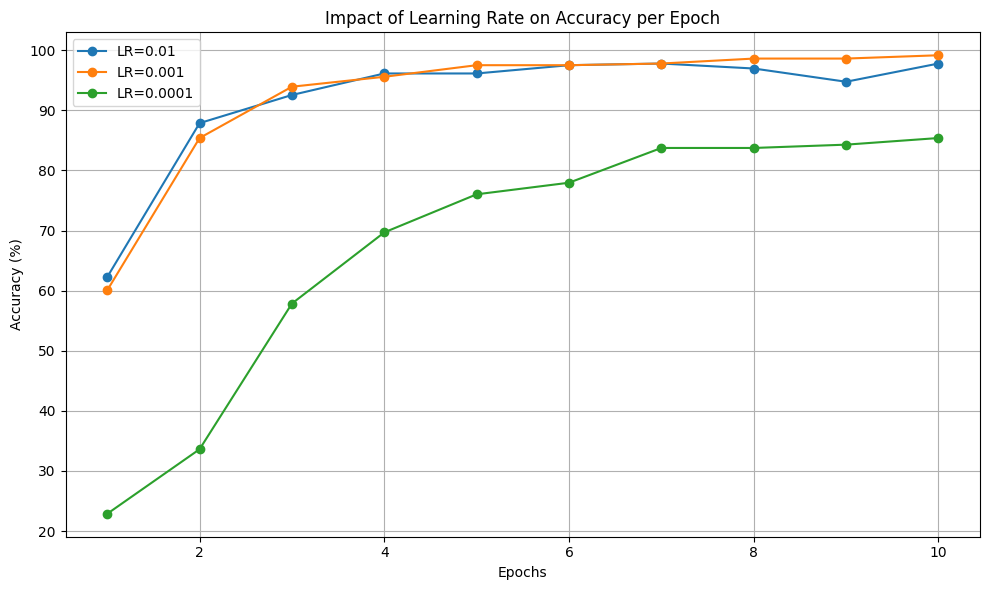


📊 Summary Table:
╒═════════════════╤══════════════════════╕
│   Learning Rate │   Final Accuracy (%) │
╞═════════════════╪══════════════════════╡
│          0.01   │              97.7961 │
├─────────────────┼──────────────────────┤
│          0.001  │              99.1736 │
├─────────────────┼──────────────────────┤
│          0.0001 │              85.3994 │
╘═════════════════╧══════════════════════╛


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import pandas as pd
from tabulate import tabulate

learning_rates = [0.01, 0.001, 0.0001]
num_epochs = 10
results = []

# Graphs for each learning rate
plt.figure(figsize=(10, 6))

for lr in learning_rates:
  
    model = CNNModel().to(device)  # Reset clean model
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    epoch_accuracies = []  # Save accuracies per epoch

    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, optimizer, criterion, device)
        test_accuracy = evaluate(model, test_loader, device)
        epoch_accuracies.append(test_accuracy)  # Save accuracy for the epoch
        
    # Plot for each learning rate
    plt.plot(range(1, num_epochs+1), epoch_accuracies, marker='o', label=f"LR={lr}")
    
    # Save the result for the table
    results.append({'Learning Rate': lr, 'Final Accuracy (%)': epoch_accuracies[-1]})

# Graph of accuracy evolution
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Impact of Learning Rate on Accuracy per Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Create table with pandas
df_results = pd.DataFrame(results)

# Display the table using Tabulate with 'fancy_grid' format for better clarity
table = tabulate(df_results, headers='keys', tablefmt='fancy_grid', showindex=False)

# Print the table
print("\n📊 Summary Table:")
print(table)


Best learning rate : **0.001**

# 2. Batch size 
The same methodology but with the batch size
Try with : 16 , 32, 64, 128

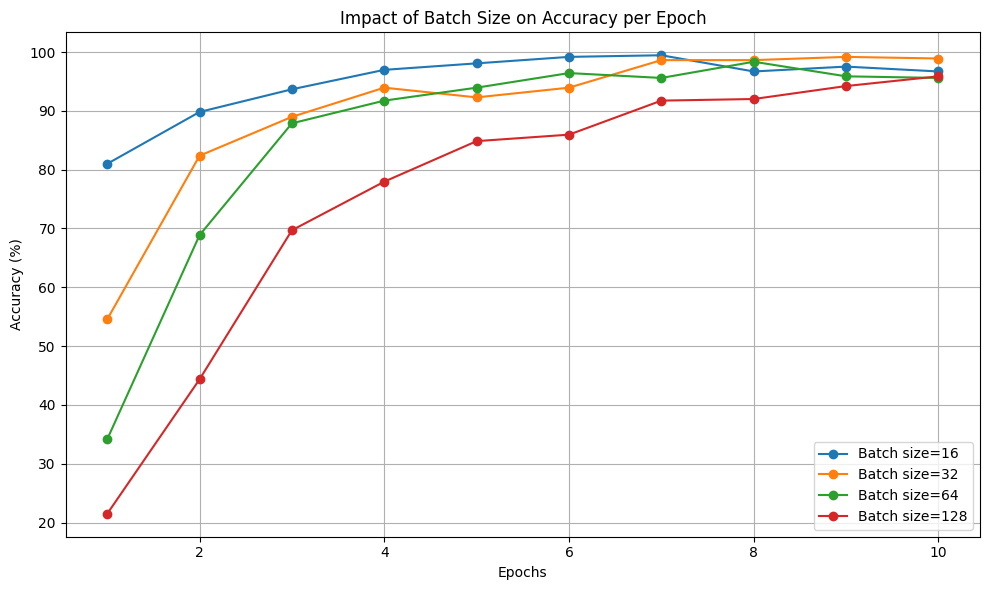


📊 Summary Table:
╒══════════════╤══════════════════════╕
│   Batch Size │   Final Accuracy (%) │
╞══════════════╪══════════════════════╡
│           16 │              96.6942 │
├──────────────┼──────────────────────┤
│           32 │              98.8981 │
├──────────────┼──────────────────────┤
│           64 │              95.5923 │
├──────────────┼──────────────────────┤
│          128 │              95.8678 │
╘══════════════╧══════════════════════╛


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import pandas as pd
from tabulate import tabulate
from torch.utils.data import DataLoader

batch_sizes = [16, 32, 64, 128]
num_epochs = 10
results = []

# Graphs for each batch size
plt.figure(figsize=(10, 6))

for batch_size in batch_sizes:
    
    model = CNNModel().to(device)  # Reset clean model
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    
    # Adjust DataLoader with the batch_size
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    epoch_accuracies = []  # Save accuracies per epoch

    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, optimizer, criterion, device)
        test_accuracy = evaluate(model, test_loader, device)
        epoch_accuracies.append(test_accuracy)  # Save accuracy for the epoch
        
    # Plot for each batch size
    plt.plot(range(1, num_epochs+1), epoch_accuracies, marker='o', label=f"Batch size={batch_size}")
    
    # Save the result for the table
    results.append({'Batch Size': batch_size, 'Final Accuracy (%)': epoch_accuracies[-1]})

# Graph of accuracy evolution
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Impact of Batch Size on Accuracy per Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Create table with pandas
df_results = pd.DataFrame(results)

# Display the table using Tabulate with 'fancy_grid' format for better clarity
table = tabulate(df_results, headers='keys', tablefmt='fancy_grid', showindex=False)

# Print the table
print("\n📊 Summary Table:")
print(table)


best batch size is **32**

# 3. N of epochs 
we try these different values in order to see how its is affected : num_epochs_list = [5, 10, 20,30]

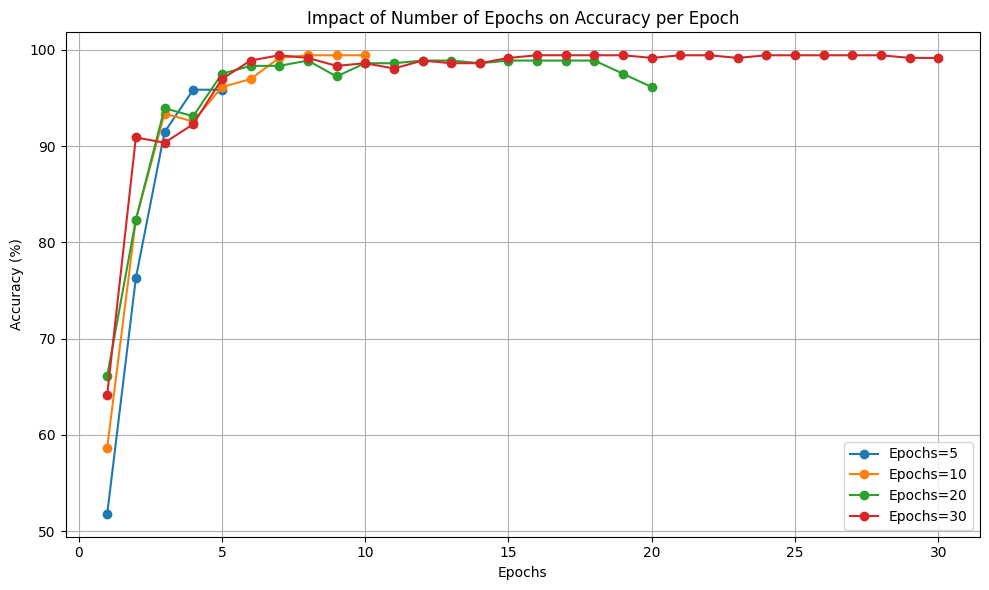


📊 Summary Table:
╒════════════════════╤══════════════════════╕
│   Number of Epochs │   Final Accuracy (%) │
╞════════════════════╪══════════════════════╡
│                  5 │              95.8678 │
├────────────────────┼──────────────────────┤
│                 10 │              99.449  │
├────────────────────┼──────────────────────┤
│                 20 │              96.1433 │
├────────────────────┼──────────────────────┤
│                 30 │              99.1736 │
╘════════════════════╧══════════════════════╛


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import pandas as pd
from tabulate import tabulate

# Hyperparameter for number of epochs
num_epochs_list = [5, 10, 20,30]
learning_rate = 0.001  # Keeping learning rate fixed for this experiment
results = []

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Graphs for each number of epochs
plt.figure(figsize=(10, 6))

for num_epochs in num_epochs_list:
  
    model = CNNModel().to(device)  # Reset clean model
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    
    epoch_accuracies = []  # Save accuracies per epoch

    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, optimizer, criterion, device)
        test_accuracy = evaluate(model, test_loader, device)
        epoch_accuracies.append(test_accuracy)  # Save accuracy for the epoch
        
    # Plot for each number of epochs
    plt.plot(range(1, num_epochs+1), epoch_accuracies, marker='o', label=f"Epochs={num_epochs}")
    
    # Save the result for the table
    results.append({'Number of Epochs': num_epochs, 'Final Accuracy (%)': epoch_accuracies[-1]})

# Graph of accuracy evolution
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.title('Impact of Number of Epochs on Accuracy per Epoch')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Create table with pandas
df_results = pd.DataFrame(results)

# Display the table using Tabulate with 'fancy_grid' format for better clarity
table = tabulate(df_results, headers='keys', tablefmt='fancy_grid', showindex=False)

# Print the table
print("\n📊 Summary Table:")
print(table)

We noticed that as much epochs it does not get better as i thought is gonna be , and the best N of epochs is in the middle **(10)**

# 4. CNN architecture 
 1. we try by adding a convolutional layer 

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        # First phase of feature extraction
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)  # output (batch_size, 32, 28, 28)
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)  # output (batch_size, 32, 14, 14)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)  # output (batch_size, 64, 14, 14)

        # Added additional convolutional layer
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1)  # output (batch_size, 128, 14, 14)

        # Second phase of classification
        self.fc1 = nn.Linear(in_features=128*7*7, out_features=128)
        self.fc2 = nn.Linear(in_features=128, out_features=num_classes)  # output = num_classes

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.maxpool(x)

        x = self.relu(self.conv2(x))
        x = self.maxpool(x)

        # Apply third convolutional layer
        x = self.relu(self.conv3(x))
        x = self.maxpool(x)

        x = x.view(x.size(0), -1)  # Flatten the tensor for fully connected layers

        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

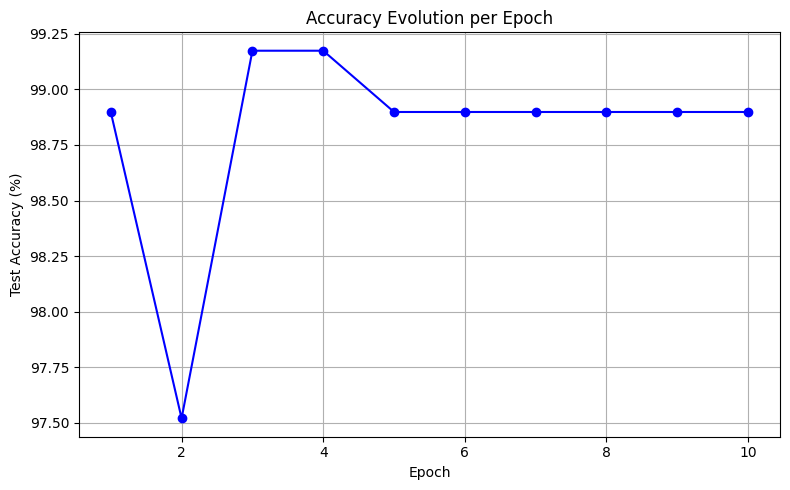

Accuracy on the test dataset: 98.90%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt  # Import for plotting

# Set the device to GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()  # Suitable for multi-class classification
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Number of epochs for training
num_epochs = 10

# List to store test accuracies for each epoch
epoch_accuracies = []

# Train the model
for epoch in range(num_epochs):
    train_loss = train(model, train_loader, optimizer, criterion, device)
    test_accuracy = evaluate(model, test_loader, device)
    epoch_accuracies.append(test_accuracy)  # Save accuracy
  

# Plot accuracy evolution
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), epoch_accuracies, marker='o', color='blue')
plt.title('Accuracy Evolution per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Final evaluation
model.eval()  # Set model to evaluation mode
correct = 0
total = 0
with torch.no_grad():  # Disable gradient calculation for evaluation
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Accuracy on the test dataset: {accuracy:.2f}%")

we add another Conv layer 

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CNNModel(nn.Module):
    def __init__(self):
        super().__init__()
        # First phase of feature extraction
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, stride=1, padding=1)  # -> (32, 28, 28)
        self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)  # -> (32, 14, 14)
        self.relu = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=1)  # -> (64, 14, 14)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, stride=1, padding=1)  # -> (128, 14, 14)

        # ➕ New fourth convolutional layer
        self.conv4 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1)  # -> (256, 14, 14)

        # Fully connected layers
        self.fc1 = nn.Linear(in_features=256*1*1, out_features=128)  # adjusted input size
        self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.maxpool(x)

        x = self.relu(self.conv2(x))
        x = self.maxpool(x)

        x = self.relu(self.conv3(x))
        x = self.maxpool(x)

        x = self.relu(self.conv4(x))
        x = self.maxpool(x)

        x = x.view(x.size(0), -1)  # Flatten

        x = self.relu(self.fc1(x))
        x = self.fc2(x)
        return x

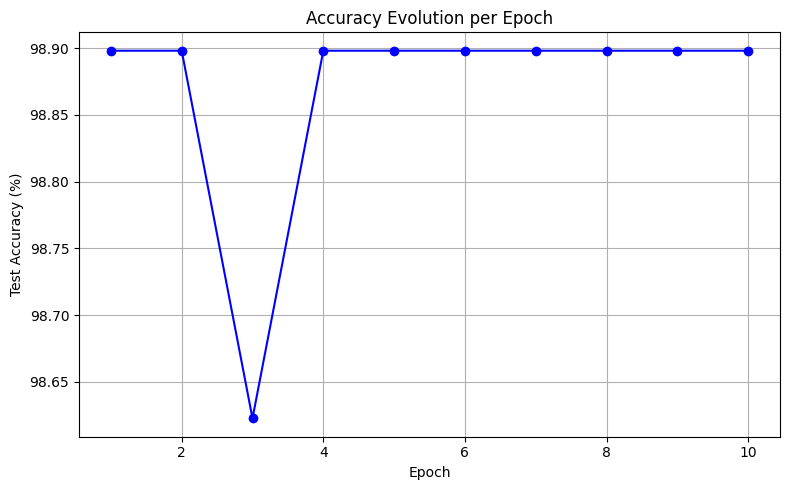

Accuracy on the test dataset: 98.90%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt  # Import for plotting

# Set the device to GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()  # Suitable for multi-class classification
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Number of epochs for training
num_epochs = 10

# List to store test accuracies for each epoch
epoch_accuracies = []

# Train the model
for epoch in range(num_epochs):
    train_loss = train(model, train_loader, optimizer, criterion, device)
    test_accuracy = evaluate(model, test_loader, device)
    epoch_accuracies.append(test_accuracy)  # Save accuracy
  

# Plot accuracy evolution
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), epoch_accuracies, marker='o', color='blue')
plt.title('Accuracy Evolution per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Final evaluation
model.eval()  # Set model to evaluation mode
correct = 0
total = 0
with torch.no_grad():  # Disable gradient calculation for evaluation
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Accuracy on the test dataset: {accuracy:.2f}%")

Although both the 3-layer and 4-layer convolutional networks achieved the same test accuracy of 98.9%, we chose the 3-layer model because it is simpler and more efficient. A simpler model requires fewer parameters, less memory, and trains faster, which reduces the risk of overfitting and makes it easier to deploy. Since the extra layer did not provide any performance improvement, it’s better to stick with the more compact architecture

We choose the **three convolutionals layers** and try different combinations of N of filters applied : 

- filter_configs = 
        (32, 64, 128),
        (64, 128, 256),
        (128, 256, 512)


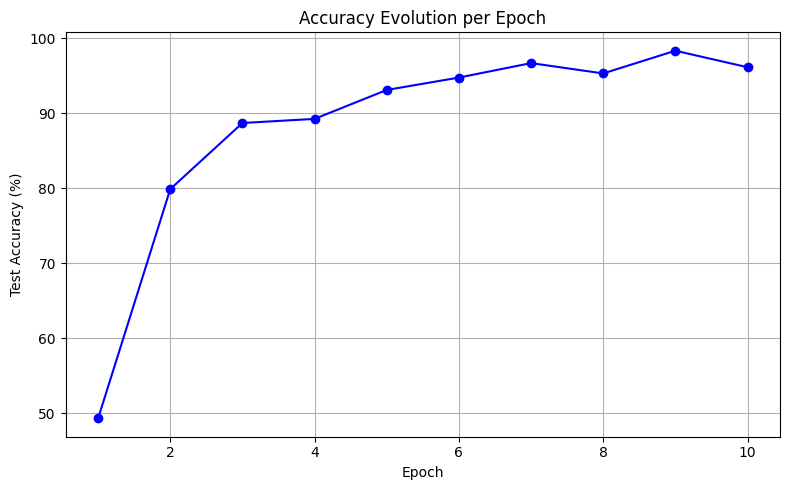

Accuracy on the test dataset (filters: 32-64-128): 96.14%


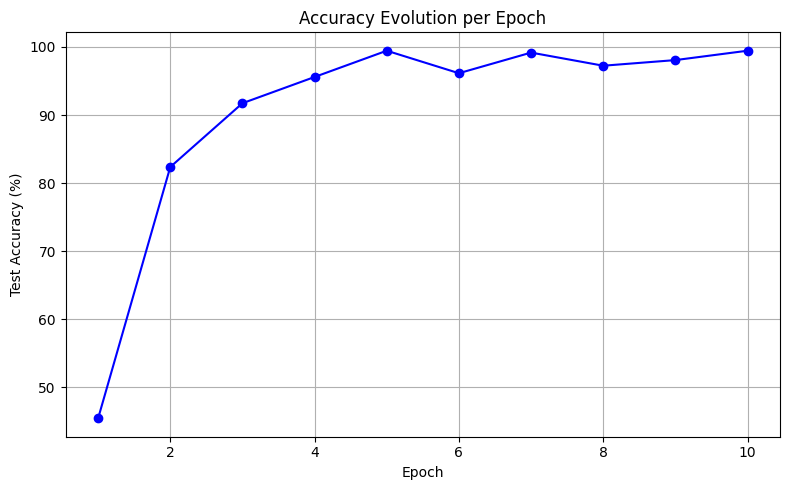

Accuracy on the test dataset (filters: 64-128-256): 99.45%


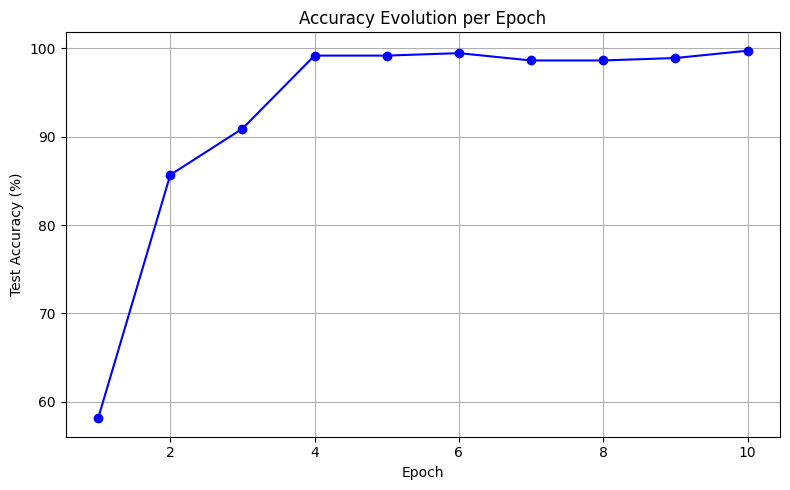

Accuracy on the test dataset (filters: 128-256-512): 99.72%


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Simulación de múltiples configuraciones de filtros
filter_configs = [
    (32, 64, 128),
    (64, 128, 256),
    (128, 256, 512)
]

models = []

for f1, f2, f3 in filter_configs:
    class CNNModel(nn.Module):
        def __init__(self):
            super().__init__()
            self.relu = nn.ReLU()
            self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

            self.conv1 = nn.Conv2d(in_channels=3, out_channels=f1, kernel_size=3, stride=1, padding=1)
            self.conv2 = nn.Conv2d(in_channels=f1, out_channels=f2, kernel_size=3, stride=1, padding=1)
            self.conv3 = nn.Conv2d(in_channels=f2, out_channels=f3, kernel_size=3, stride=1, padding=1)

            self.fc1 = nn.Linear(in_features=f3 * 3 * 3, out_features=128)
            self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

        def forward(self, x):
            x = self.relu(self.conv1(x))
            x = self.maxpool(x)
            x = self.relu(self.conv2(x))
            x = self.maxpool(x)
            x = self.relu(self.conv3(x))
            x = self.maxpool(x)
            x = x.view(x.size(0), -1)
            x = self.relu(self.fc1(x))
            return self.fc2(x)

    model = CNNModel()
  

 

    # Set the device to GPU if available, otherwise CPU
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    # Define loss function and optimizer
    criterion = nn.CrossEntropyLoss()  # Suitable for multi-class classification
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Number of epochs for training
    num_epochs = 10

    # List to store test accuracies for each epoch
    epoch_accuracies = []

    # Train the model
    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, optimizer, criterion, device)
        test_accuracy = evaluate(model, test_loader, device)
        epoch_accuracies.append(test_accuracy)  # Save accuracy
    

    # Plot accuracy evolution
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, num_epochs + 1), epoch_accuracies, marker='o', color='blue')
    plt.title('Accuracy Evolution per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Test Accuracy (%)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Final evaluation
    model.eval()  # Set model to evaluation mode
    correct = 0
    total = 0
    with torch.no_grad():  # Disable gradient calculation for evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Accuracy on the test dataset (filters: {f1}-{f2}-{f3}): {accuracy:.2f}%")

    



The best N of filters result to be the **128, 256 , 512**

The last thing to change is the size of the kernel
- kernel_configs = [
    (3, 3, 3),
    (5, 3, 3),
    (5, 5, 3),
    (7, 5, 3)
]
we decide to not change the kernel in the pooling because the standard size is 2 x 2  and its reduce the dimensions in half which i think its good

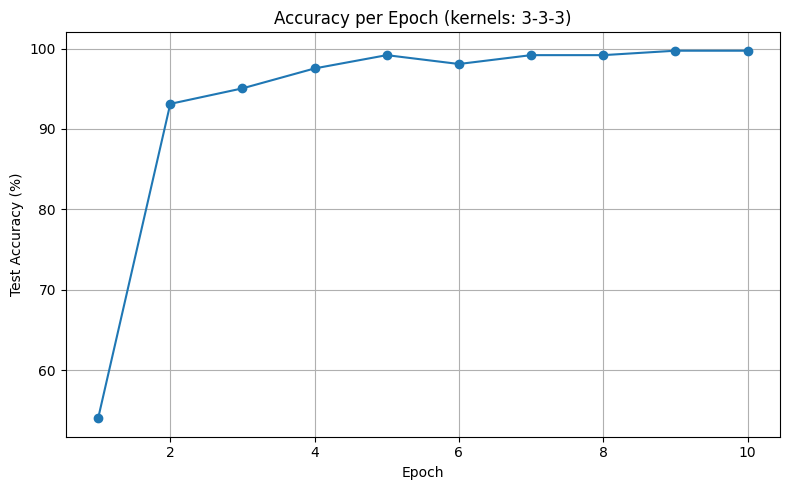

Accuracy on the test dataset (kernels: 3-3-3): 99.72%


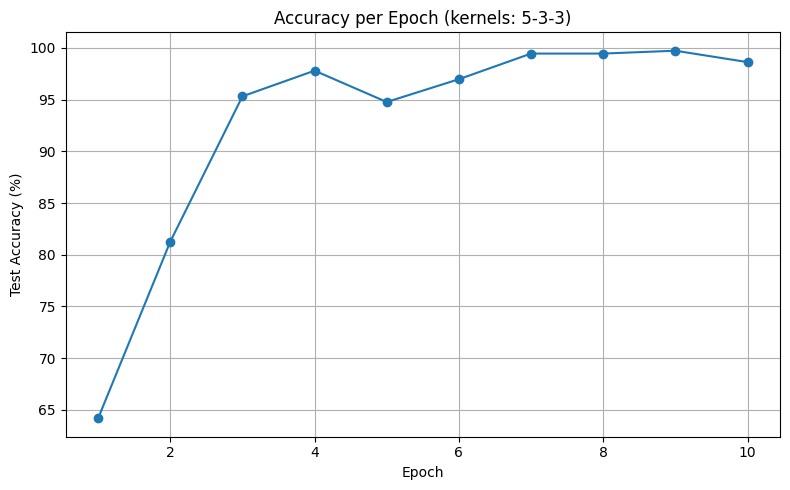

Accuracy on the test dataset (kernels: 5-3-3): 98.62%


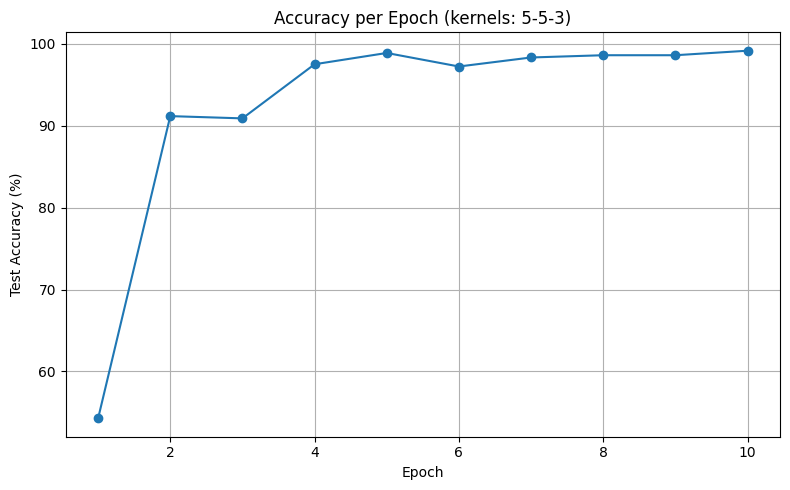

Accuracy on the test dataset (kernels: 5-5-3): 99.17%


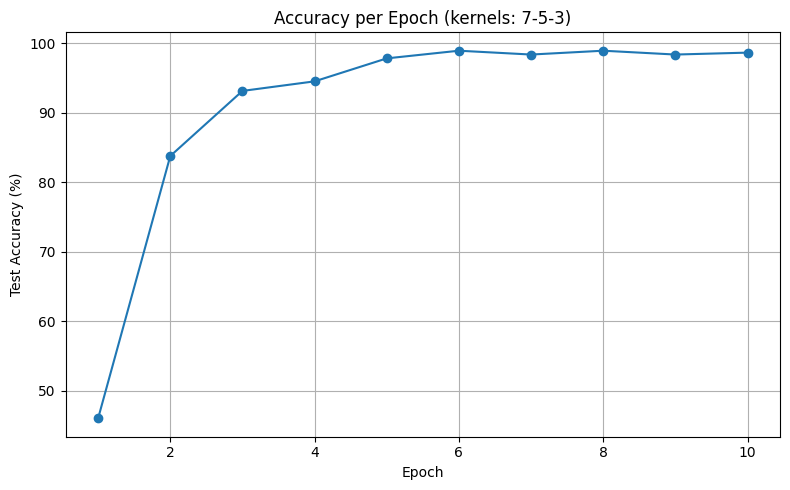

Accuracy on the test dataset (kernels: 7-5-3): 98.62%


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Kernel size configurations for conv1, conv2, conv3
kernel_configs = [
    (3, 3, 3),
    (5, 3, 3),
    (5, 5, 3),
    (7, 5, 3)
]

for k1, k2, k3 in kernel_configs:
    class CNNModel(nn.Module):
        def __init__(self):
            super().__init__()
            self.relu = nn.ReLU()
            self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

            self.conv1 = nn.Conv2d(in_channels=3, out_channels=128, kernel_size=k1, stride=1, padding=k1 // 2)
            self.conv2 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=k2, stride=1, padding=k2 // 2)
            self.conv3 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=k3, stride=1, padding=k3 // 2)

            self.fc1 = nn.Linear(in_features=512 * 3 * 3, out_features=128)
            self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

        def forward(self, x):
            x = self.relu(self.conv1(x))
            x = self.maxpool(x)
            x = self.relu(self.conv2(x))
            x = self.maxpool(x)
            x = self.relu(self.conv3(x))
            x = self.maxpool(x)
            x = x.view(x.size(0), -1)
            x = self.relu(self.fc1(x))
            return self.fc2(x)

    # Entrenamiento
    model = CNNModel()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    num_epochs = 10
    epoch_accuracies = []

    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, optimizer, criterion, device)
        test_accuracy = evaluate(model, test_loader, device)
        epoch_accuracies.append(test_accuracy)

    # Plot
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, num_epochs + 1), epoch_accuracies, marker='o')
    plt.title(f'Accuracy per Epoch (kernels: {k1}-{k2}-{k3})')
    plt.xlabel('Epoch')
    plt.ylabel('Test Accuracy (%)')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # Evaluación final
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    print(f"Accuracy on the test dataset (kernels: {k1}-{k2}-{k3}): {accuracy:.2f}%")

The best kernel combination is the **3 - 3 - 3** with accuracy of 99,72%

We decided not to change the stride and keep it at 1 to avoid complications. Changing the stride affects the size of the feature maps, which can break the connection with the fully connected layers if not adjusted carefully. Also, using stride = 1 helps preserve more information in the images and makes the model easier to train without needing to recalculate dimensions every time.

Also this logic applied to the padding 

# 5. Activations Function 

In [ ]:
from tabulate import tabulate

activations = {
    'ReLU': nn.ReLU(),
    'LeakyReLU': nn.LeakyReLU(),
    'Sigmoid': nn.Sigmoid(),
    'Tanh': nn.Tanh()
}

results = []

for name, activation_fn in activations.items():
    class CNNModel(nn.Module):
        def __init__(self):
            super().__init__()
            self.activation = activation_fn
            self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

            self.conv1 = nn.Conv2d(in_channels=3, out_channels=128, kernel_size=3, stride=1, padding=1)
            self.conv2 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1)
            self.conv3 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding=1)

            self.fc1 = nn.Linear(in_features=512 * 3 * 3, out_features=128)
            self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

        def forward(self, x):
            x = self.activation(self.conv1(x))
            x = self.maxpool(x)
            x = self.activation(self.conv2(x))
            x = self.maxpool(x)
            x = self.activation(self.conv3(x))
            x = self.maxpool(x)
            x = x.view(x.size(0), -1)
            x = self.activation(self.fc1(x))
            return self.fc2(x)

    # Entrenamiento
    model = CNNModel().to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    num_epochs = 10
    epoch_accuracies = []

    for epoch in range(num_epochs):
        train_loss = train(model, train_loader, optimizer, criterion, device)
        test_accuracy = evaluate(model, test_loader, device)
        epoch_accuracies.append(test_accuracy)

    final_accuracy = epoch_accuracies[-1]
    results.append([name, f"{final_accuracy:.2f}%"])

# Mostrar la tabla
headers = ["Activation Function", "Final Test Accuracy"]
print(tabulate(results, headers=headers, tablefmt="fancy_grid"))

╒═══════════════════════╤═══════════════════════╕
│ Activation Function   │ Final Test Accuracy   │
╞═══════════════════════╪═══════════════════════╡
│ ReLU                  │ 98.62%                │
├───────────────────────┼───────────────────────┤
│ LeakyReLU             │ 99.45%                │
├───────────────────────┼───────────────────────┤
│ Sigmoid               │ 3.31%                 │
├───────────────────────┼───────────────────────┤
│ Tanh                  │ 99.17%                │
╘═══════════════════════╧═══════════════════════╛


This result to be the **Tanh** the best activation function but i noticed that we get better accuracy with the previous compilation and we use Relu on there so im gonna stuck with relu in spite of this result 
- : **relu : 99,72% > LeakyRelu : 99.45%**

# 6. we vary the optimizer and the loss function 

-   optimizers = {
        'Adam': optim.Adam,
        'SGD': optim.SGD,
    }

-   loss_functions = {
        'CrossEntropyLoss': nn.CrossEntropyLoss,
        'NLLLoss': nn.NLLLoss
    }

In [ ]:
from tabulate import tabulate

# Combinaciones de optimizadores y funciones de pérdida
optimizers = {
    'Adam': optim.Adam,
    'SGD': optim.SGD,
}

loss_functions = {
    'CrossEntropyLoss': nn.CrossEntropyLoss,
    'NLLLoss': nn.NLLLoss
}

results = []

for opt_name, opt_class in optimizers.items():
    for loss_name, loss_fn_class in loss_functions.items():
        class CNNModel(nn.Module):
            def __init__(self):
                super().__init__()
                self.activation = nn.ReLU()
                self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

                self.conv1 = nn.Conv2d(in_channels=3, out_channels=128, kernel_size=3, stride=1, padding=1)
                self.conv2 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1)
                self.conv3 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding=1)

                self.fc1 = nn.Linear(in_features=512 * 3 * 3, out_features=128)
                self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

                # Si la función de pérdida es NLLLoss, se usa LogSoftmax en la salida
                if loss_name == "NLLLoss":
                    self.output_activation = nn.LogSoftmax(dim=1)
                else:
                    self.output_activation = nn.Identity()

            def forward(self, x):
                x = self.activation(self.conv1(x))
                x = self.maxpool(x)
                x = self.activation(self.conv2(x))
                x = self.maxpool(x)
                x = self.activation(self.conv3(x))
                x = self.maxpool(x)
                x = x.view(x.size(0), -1)
                x = self.activation(self.fc1(x))
                x = self.fc2(x)
                return self.output_activation(x)

        # Entrenamiento
        model = CNNModel().to(device)
        optimizer = opt_class(model.parameters(), lr=0.001)
        criterion = loss_fn_class().to(device)

        num_epochs = 10
        epoch_accuracies = []

        for epoch in range(num_epochs):
            train_loss = train(model, train_loader, optimizer, criterion, device)
            test_accuracy = evaluate(model, test_loader, device)
            epoch_accuracies.append(test_accuracy)

        final_accuracy = epoch_accuracies[-1]
        results.append([opt_name, loss_name, f"{final_accuracy:.2f}%"])

# Mostrar la tabla
headers = ["Optimizer", "Loss Function", "Final Test Accuracy"]
print(tabulate(results, headers=headers, tablefmt="fancy_grid"))

╒═════════════╤══════════════════╤═══════════════════════╕
│ Optimizer   │ Loss Function    │ Final Test Accuracy   │
╞═════════════╪══════════════════╪═══════════════════════╡
│ Adam        │ CrossEntropyLoss │ 99.72%                │
├─────────────┼──────────────────┼───────────────────────┤
│ Adam        │ NLLLoss          │ 99.72%                │
├─────────────┼──────────────────┼───────────────────────┤
│ SGD         │ CrossEntropyLoss │ 4.68%                 │
├─────────────┼──────────────────┼───────────────────────┤
│ SGD         │ NLLLoss          │ 5.51%                 │
╘═════════════╧══════════════════╧═══════════════════════╛


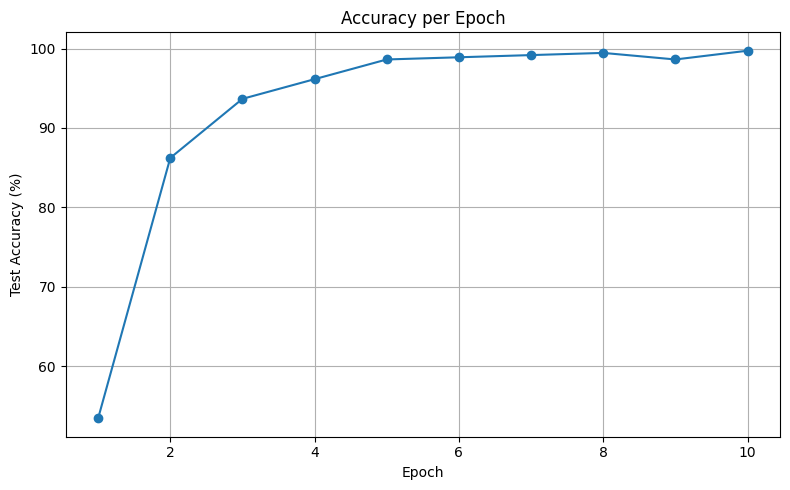

Accuracy on the test dataset : 99.72%


In [ ]:
class CNNModel(nn.Module):
        def __init__(self):
            super().__init__()
            self.relu = nn.ReLU()
            self.maxpool = nn.MaxPool2d(kernel_size=2, stride=2)

            self.conv1 = nn.Conv2d(in_channels=3, out_channels=128, kernel_size=3, stride=1, padding=1)
            self.conv2 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=3, stride=1, padding=1)
            self.conv3 = nn.Conv2d(in_channels=256, out_channels=512, kernel_size=3, stride=1, padding=1)

            self.fc1 = nn.Linear(in_features=512 * 3 * 3, out_features=128)
            self.fc2 = nn.Linear(in_features=128, out_features=num_classes)

        def forward(self, x):
            x = self.relu(self.conv1(x))
            x = self.maxpool(x)
            x = self.relu(self.conv2(x))
            x = self.maxpool(x)
            x = self.relu(self.conv3(x))
            x = self.maxpool(x)
            x = x.view(x.size(0), -1)
            x = self.relu(self.fc1(x))
            return self.fc2(x)

# Entrenamiento
model = CNNModel()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10
epoch_accuracies = []

for epoch in range(num_epochs):
    rain_loss = train(model, train_loader, optimizer, criterion, device)
    test_accuracy = evaluate(model, test_loader, device)
    epoch_accuracies.append(test_accuracy)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), epoch_accuracies, marker='o')
plt.title(f'Accuracy per Epoch' )
plt.xlabel('Epoch')
plt.ylabel('Test Accuracy (%)')
plt.grid(True)
plt.tight_layout()
plt.show()

# Evaluación final
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Accuracy on the test dataset : {accuracy:.2f}%")

# Conclusions of hyperparameters 

## Introduction
In this analysis, we tested different hyperparameter combinations to optimize the performance of our classification model. The Hyperparameters tested are the followings : **Learning Rate** , **Batch Size** , **N of epochs**, **CN architecture(N filters , N of layers , Stride and padding)** , **Activation functions** and **Optimizers**

## Hyperparameter 1: of the Learning rate 
The **learning rate** is one of the most important parameters when training a machine learning model. It controls the size of the steps the optimizer takes at each iteration. If the learning rate is too high, the model might miss the best solutions, while if it's too low, the training might become too slow or stall. 

### Results

We tested three learning rates: 0.01, 0.001, and 0.0001. The learning rate of **0.001** performed the best overall, achieving the highest final accuracy over all the tests we did 

## Hyperparameter 2: Batch Size

**Batch size** is the number of samples processed before the model updates its parameters. A small batch size can lead to faster learning, but might result in higher variability in the accuracy. A larger batch size usually reduces variability but makes the training slower.

### Results

We tested different batch sizes, such as 16, 32, 64 and 128. The results showed that a batch size of **32** provided a good balance between training time and final accuracy.

## Hyperparameter 3 : N of epochs 

The **number of epochs** is the number of times the model sees the entire dataset during training. Generally, more epochs allow the model to learn better, but it can also lead to overfitting if the model learns the training data too well or vice versa: underfitting.

### Results
We tried these values : 5 ,10, 20, 30. The best accuracy in your CNN appears at 10 epochs because it’s the most reasonable balance between underfitting and overfitting. With 5 epochs, the model may not have learned enough patterns from the data yet. With 20 or 30 epochs, the model might start overfitting—memorizing the training data instead of generalizing well to unseen data. Therefore, **10 epochs** offer a sweet spot where the model learns enough without starting to overfit.

## Hyperparameter 4 : CNN Architecture 

### N of layers 
I have tested up two four convolutional layers and it tend to give the best performance the one with **three convolutional layers** .

Using 3 convolutional layers gives the best accuracy because it’s a good trade-off between model complexity and feature extraction. With only 2 layers, the model might not **capture enough high-level features**. With 4 layers, the model could become too complex and start **overfitting**, especially if the dataset isn’t very large. Three layers allow the CNN to learn both low-level and high-level patterns effectively without becoming too deep.

### N of filters applied 

We have tested with these combinations :
- (32, 64, 128),
- (64, 128, 256),
- (128, 256, 512)

The best combination result to be the (128, 256, 512)

The number of filters determines how many features the model can extract at each layer. More filters allow the CNN to learn more complex and detailed patterns from the images.

The best performance came from **(128, 256, 512)** because this combination gives the model a higher capacity to detect fine-grained features and deeper structures in the images. While it increases computational cost, it leads to better accuracy since the model can learn more expressive and powerful representations of the data.

### N of kernels 
We have tried these combinations of kernels 

- (3, 3, 3),
- (5, 3, 3),
- (5, 5, 3),
- (7, 5, 3)

The kernel size affects how much of the image the model “looks at” when extracting features. Smaller kernels like 3x3 focus on fine details and allow the network to go deeper while maintaining control over the number of parameters.

The best performance came from **(3, 3, 3)** because small kernels help the model learn detailed patterns step by step, layer by layer. They also reduce the risk of overfitting and make the model more efficient. This setup is often effective because stacking multiple 3x3 convolutions can capture complex features while keeping the architecture simple and powerful.

### Padding and stride 
I have decided to not change this values because 

I decided not to change these values because using **stride = 1 and padding = 1** helps the model keep the size of the images almost the same after each convolution. This way, the model can learn more details without making the images too small too quickly. If I increased the stride or changed the padding, the model might miss important parts of the image, which could reduce accuracy.

## Hyperparameter 5 : Activation Functions
i have tried these examples : Relu , LikelyRelu , Tanh , sigmoid .
The best one was the relu in previous examples so we choose the relu over the likely relu that was thes best in performance 

## Hyperparameter 6 : Optimizers and loss function

We tested two combinations of **loss function** (CrossEntropyLoss and NLLLoss) and **optimizers** (Adam and SGD). The loss function measures how far the model's predictions are from the actual labels. Optimizers like **Adam** and **SGD** update the model's weights based on the gradients calculated.

### Results

The combination of **CrossEntropyLoss** with **Adam** optimizer was the most effective in terms of final accuracy. Adam adapts the learning rate during training, which helps improve convergence.


## Final conclusion 
The best combination of hyperparameter is : **Learning rate of 0.001** , **Batch size of 32** , **N of epochs : 10** , **3 conv layers** , **128-256-512 filters** , **3 - 3 - 3 kernels** , **Relu act F**  and **Crossentropyloss , and adam***

All this giving and accuracy of 99.72% which is almost perfect 


